# The TODCOR method, derived in the open

This notebook derives the two-component (double-lined) velocity estimator in `todcor` from
scratch and checks every claim with a printed number: the "no black box" companion to
[`todcor_method.md`](../../../packages/todcor/docs/todcor_method.md). The *applied* fits live in `02_single_window_fit` and
`03_multiwindow_combination`.

The templates are synthetic, so the notebook is self-contained (no external data); the engine
treats any template the same way. The checks, in order: the shift theorem; why the templates
are extended past the window; the free offset and the centred (Pearson-like) sums it leaves;
the six sufficient statistics; the closed-form amplitudes; profile vs marginal likelihood.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# The TODCOR engine, its forward model, and the shared grid/FFT primitives
# (re-exported from unicor.dsp) all live in one namespace.
import todcor as tf

# The SPARTA figure style: data black steps, models red, one extra series
# blue, maps as grey-scale images with the peak black.
from sparta.plotting import (GREY, apply_style, DLNL_LABEL, map_colorbar, map_image,
                             mark_fit, mark_truth, plot_extra, plot_model)
apply_style()

C = tf.C_KMS  # speed of light, km/s

# One Gaussian absorption or emission line: the building block of the templates
def gauss_line(wave, center, depth, fwhm_kms, emission=False):
    "A single Gaussian absorption (or emission) line on a wavelength grid."
    sigma = (fwhm_kms / 2.3548) * center / C
    prof = depth * np.exp(-0.5 * ((wave - center) / sigma) ** 2)
    return 1.0 + prof if emission else 1.0 - prof

# The rest-frame templates: finely sampled (0.5 km/s) and wider than any window, as real ones are.
# Two components: an OB-like absorber (primary) + a WR-like broad emitter (secondary).
wave_t, _ = tf.log_lambda_grid(4560.0, 4760.0, 0.5)
tmpl1 = (wave_t, gauss_line(wave_t, 4634., 0.25, 120.) * gauss_line(wave_t, 4686., 0.15, 120.))
tmpl2 = (wave_t, gauss_line(wave_t, 4686., 0.60, 400., emission=True))

# The observed window: a uniform log-lambda grid (constant velocity step dv, km/s)
dv = 3.0
wave, u = tf.log_lambda_grid(4600.0, 4720.0, dv)
print(f"window: {wave[0]:.0f}-{wave[-1]:.0f} Å, N={len(wave)} pixels, dv={dv} km/s; "
      f"templates {wave_t[0]:.0f}-{wave_t[-1]:.0f} Å")

window: 4600-4720 Å, N=2574 pixels, dv=3.0 km/s; templates 4560-4760 Å


## 1. A Doppler shift is a phase factor

On a log-λ grid a velocity shift `s = c·ln(1 + v/c)` (km/s) is a pure *translation*, so in the
Fourier domain it is a phase factor `exp(−2πiζs)` (the shift theorem): one transform of a
template serves every trial velocity, and a fractional shift is a band-limited interpolation.
Check it: shift a template by physical resampling and by the Fourier phase.

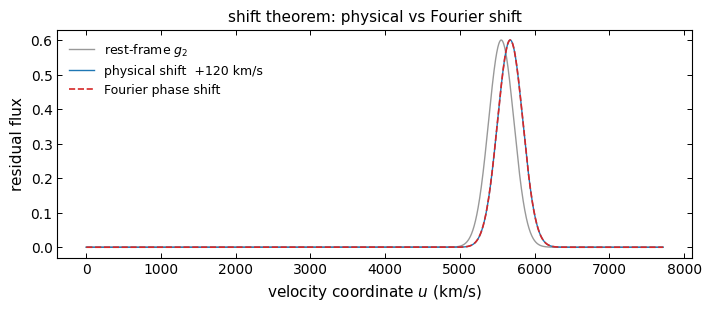

max |physical - Fourier| = 2.6656271190361736e-08


In [2]:
# Reference: shift the secondary template by +120 km/s by physical resampling
v_test = 120.0
g2 = tf.resample(*tmpl2, wave) - 1.0                      # rest-frame residual on the window
phys = tf.shift_template_flux(*tmpl2, wave, v_test) - 1.0
# The same shift in Fourier space: multiply the spectrum by the phase exp(-2 pi i zeta s)
zeta = np.fft.rfftfreq(len(g2), d=dv)
four = np.fft.irfft(np.fft.rfft(g2) * np.exp(-2j * np.pi * zeta * tf.shift_kms(v_test)), n=len(g2))

# Plot the rest-frame template against the two shifted versions
fig, ax = plt.subplots(figsize=(7, 3.0))
ax.plot(u, g2, color=GREY, label="rest-frame $g_2$")
plot_extra(ax, u, phys, label=f"physical shift  +{v_test:.0f} km/s")
plot_model(ax, u, four, ls="--", label="Fourier phase shift")
ax.set_xlabel("velocity coordinate $u$ (km/s)"); ax.set_ylabel("residual flux")
ax.set_title("shift theorem: physical vs Fourier shift"); ax.legend()
plt.show()
# The two shifts must agree to the interpolation error
print("max |physical - Fourier| =", np.max(np.abs(phys - four)))

## 2. Extend the template, so the wrap stays outside the window

The phase factor shifts *circularly*: what leaves one end of the array re-enters at the other.
Above that was harmless, as both ends of the window are flat continuum. A real window is cut
out of a spectrum, and a line shifted out of one end comes back at the other end as a ghost,
while the line that should enter from beyond the edge is missing. The fit therefore keeps the
*observed* pixels only, but shifts each template on the window's grid **extended** by `e`
pixels on each side, `e` at least the largest shift, and reads the central `n` pixels. What
wraps around then lands in the extension, never in the window. An odd total length leaves no
Nyquist mode, so the phase-shifted array stays real. Check it on a window whose blue edge sits
next to the primary's 4634 Å line, shifted by −300 km/s:

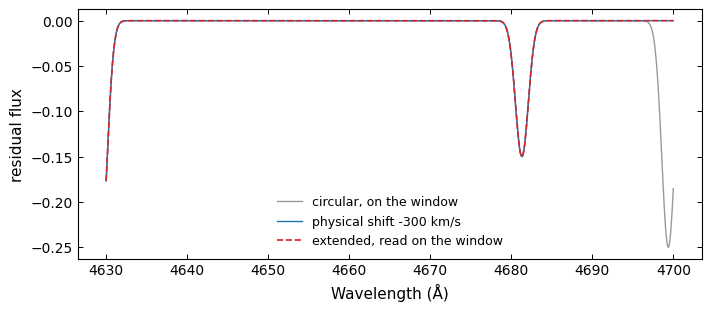

max |circular - physical| = 0.250
max |extended - physical| = 1.0e-06  (first/last 10 pixels: 5.7e-07 / 1.4e-16)


In [3]:
# A window whose blue edge sits 4 Å from the primary's 4634 Å line
ww = wave[(wave >= 4630.0) & (wave <= 4700.0)]
n = ww.size
v_s = -300.0
pixels = tf.shift_kms(v_s) / dv                           # the shift, in pixels
physical = tf.shift_template_flux(*tmpl1, ww, v_s) - 1.0  # the reference

# Shift an array by a (fractional) number of pixels with the phase factor of its own FFT
def phase_shift(g, pixels):
    f = np.fft.rfftfreq(g.size)                           # cycles per pixel
    return np.fft.irfft(np.fft.rfft(g) * np.exp(-2j * np.pi * f * pixels), n=g.size)

# (a) Circular: the template on the window's own pixels
circular = phase_shift(tf.resample(*tmpl1, ww) - 1.0, pixels)
# (b) Extended: the template on the window's grid continued by e pixels per side, odd length
e = int(np.ceil(abs(pixels))) + 20
e += (n + 2 * e + 1) % 2
ext = ww[0] * np.exp(dv / C * np.arange(-e, n + e))
extended = phase_shift(tf.resample(*tmpl1, ext) - 1.0, pixels)[e:e + n]

# Plot the three shifted templates on the window
fig, ax = plt.subplots(figsize=(7, 3.0))
ax.plot(ww, circular, color=GREY, label="circular, on the window")
plot_extra(ax, ww, physical, label=f"physical shift {v_s:.0f} km/s")
plot_model(ax, ww, extended, ls="--", label="extended, read on the window")
ax.set_xlabel("Wavelength (Å)"); ax.set_ylabel("residual flux"); ax.legend(loc="lower center")
plt.show()
# The circular shift puts a ghost line at the red end; the extended one matches everywhere
print(f"max |circular - physical| = {np.max(np.abs(circular - physical)):.3f}")
print(f"max |extended - physical| = {np.max(np.abs(extended - physical)):.1e}  "
      f"(first/last 10 pixels: {np.max(np.abs((extended - physical)[:10])):.1e} / "
      f"{np.max(np.abs((extended - physical)[-10:])):.1e})")

`prepare_window` builds the same extended templates (from `v_max`, plus a 20-pixel ramp to zero
at both outer ends, which keeps the extended array smooth across its own wrap-around junction;
it also removes medians, which do not matter, see §3), and `model_flux` shifts them and reads
the window, as the fit does. The library reproduces the hand-made shift up to that constant:

In [4]:
# The library's extended templates for this window, and its shift of the primary's
win_s = tf.prepare_window(ww, np.ones(n), *tmpl1, *tmpl2, v_max=abs(v_s))
lib = tf.model_flux(win_s.g1, win_s.g2, n, win_s.dv, v_s, 0.0, 1.0, 0.0)
# Equal to the hand-made shift up to a constant (the template's median)
diff = lib - extended
print(f"extension {win_s.extension} pixels per side, total length {win_s.g1.size} (odd); "
      f"max |library - by hand - constant| = {np.max(np.abs(diff - diff.mean())):.1e}")

extension 122 pixels per side, total length 1745 (odd); max |library - by hand - constant| = 2.3e-13


## 3. A free offset per window: centred, Pearson-like sums

The model of a window's observed pixels is
$d_n = a_1 G_{1n}(v_1) + a_2 G_{2n}(v_2) + c + \text{noise}$, where $G_i(v)$ is template $i$
shifted to $v$ and read on the window (§2) and $c$ is a free offset: the window's continuum
level, never set by hand. With equal pixel weights $w$, minimising
$\chi^2 = w\sum_n (d_n - a_1G_{1n} - a_2G_{2n} - c)^2$ over $c$ gives $c$ = the mean residual,
and leaves $\chi^2 = w\sum_n (r_n - \bar r)^2$: every sum is *centred*. Write
$\langle x, y\rangle = w\sum_n (x_n - \bar x)(y_n - \bar y)$. With one template the
normalised cross term $\langle d, G\rangle / \sqrt{\langle d,d\rangle\langle G,G\rangle}$ is
the Pearson correlation of data and shifted template over the window: UNICOR's per-lag CCF.
The offset costs one noise degree of freedom: `window_stats` reports `nu = n − 1` here.

The data for the rest of the notebook: a noisy composite on the full window.

In [5]:
# Truth (km/s, light fractions) and noise; a noisy composite built by physical shifting
v1t, v2t, a1t, a2t = 80.0, -160.0, 0.7, 0.55
rng = np.random.default_rng(0); sigma = 0.01
data = tf.composite_flux(wave, [tmpl1, tmpl2], [v1t, v2t], [a1t, a2t]) + rng.normal(0, sigma, len(wave))

# Trial velocity grids (km/s) for the two components
v1g = np.arange(-300, 301, 4.0)
v2g = np.arange(-400, 401, 4.0)
# Prepare the window: templates extended past it by the largest trial velocity
win = tf.prepare_window(wave, data, *tmpl1, *tmpl2, v_max=400.0)
N = win.wave.size
# The six statistics once, for every trial (v1, v2), at unit oversampling
st = tf.window_stats(win.data_g, win.g1, win.g2, win.dv, v1g, v2g, sigma=sigma)

# Check 1: the offset is profiled out, so adding a constant to the data changes nothing
st_c = tf.window_stats(win.data_g + 0.3, win.g1, win.g2, win.dv, v1g, v2g, sigma=sigma)
print("data + 0.3: max relative change of b1, SD =",
      max(np.max(np.abs(st_c["b1"] - st["b1"])) / np.max(np.abs(st["b1"])),
          abs(st_c["SD"] - st["SD"]) / st["SD"]))
# Check 2: c1 = b1 / sqrt(S11 SD) is the Pearson correlation of data and shifted template
i = 95                                                    # v1 = +80 km/s
G1 = tf.model_flux(win.g1, win.g2, N, win.dv, v1g[i], 0.0, 1.0, 0.0)
c1 = st["b1"][i] / np.sqrt(st["S11"][i] * st["SD"])
print(f"v1 = {v1g[i]:+.0f} km/s: b1/sqrt(S11 SD) = {c1:.12f}, "
      f"np.corrcoef = {np.corrcoef(win.data_g, G1)[0, 1]:.12f}")
# Check 3: the offset costs one noise degree of freedom: <noise, noise> averages n - 1 = nu
rng_noise = np.random.default_rng(1)
SD_noise = np.concatenate([np.sum((x - x.mean(axis=1, keepdims=True))**2, axis=1) / sigma**2
                           for x in (rng_noise.normal(0, sigma, (4000, N)) for _ in range(5))])
print(f"pure noise: mean <d, d> = {SD_noise.mean():.1f} +- {SD_noise.std() / np.sqrt(SD_noise.size):.1f}, "
      f"nu = {st['nu']:.0f} (n = {N})")

data + 0.3: max relative change of b1, SD = 1.7307667504966995e-15
v1 = +80 km/s: b1/sqrt(S11 SD) = 0.237301334358, np.corrcoef = 0.237301334358


pure noise: mean <d, d> = 2573.0 +- 0.5, nu = 2573 (n = 2574)


## 4. The six sufficient statistics

Expanding the centred $\chi^2$ gives, at **any** `(v1, v2, a1, a2)`, a fixed quadratic form in six
statistics (`window_stats`; with `oversampling` $M$ the weight is $w = 1/(\sigma^2 M)$):

$$S_D=\langle d,d\rangle,\quad S_{11}(v_1)=\langle G_1,G_1\rangle,\quad S_{22}(v_2)=\langle G_2,G_2\rangle,$$
$$b_1(v_1)=\langle d,G_1\rangle,\quad b_2(v_2)=\langle d,G_2\rangle,\quad A_{12}(v_1,v_2)=\langle G_1,G_2\rangle,$$

$$\chi^2 = S_D - 2(a_1 b_1 + a_2 b_2) + a_1^2 S_{11} + 2 a_1 a_2 A_{12} + a_2^2 S_{22}.$$

The template powers depend on velocity: as a template shifts, its lines move into and out of the
window. (A circular shift only permutes the window's own pixels, under which they were constant.)
$A_{12}$ depends on both velocities, not only on their difference. **Sufficiency**: given these
six, the raw spectrum is never needed again. Verify by computing χ² at an arbitrary node two ways
([correlation engines § model](../../../docs/correlation_engines.md#model-and-sufficient-statistics)):

In [6]:
print("shapes:  SD scalar;  S11", st["S11"].shape, " S22", st["S22"].shape,
      " b1", st["b1"].shape, " b2", st["b2"].shape, " A12", st["A12"].shape)

# chi^2 at one arbitrary node (trial velocities i, j; amplitudes a1, a2), from the six numbers
i, j, a1, a2 = 30, 40, 0.6, 0.5
chi2_six = (st["SD"] - 2*(a1*st["b1"][i] + a2*st["b2"][j])
            + a1**2*st["S11"][i] + 2*a1*a2*st["A12"][i, j] + a2**2*st["S22"][j])
# Direct: shift both templates to the node, fit the offset (the mean residual), sum the squares
resid = win.data_g - tf.model_flux(win.g1, win.g2, N, win.dv, v1g[i], v2g[j], a1, a2)
chi2_direct = np.sum((resid - resid.mean())**2) / sigma**2
# The two chi^2 must agree to rounding error
print(f"chi^2 from 6 statistics = {chi2_six:.6f}")
print(f"chi^2 from raw spectrum = {chi2_direct:.6f}")
print(f"relative difference     = {abs(chi2_six-chi2_direct)/chi2_direct:.1e}   <- sufficiency")

# S11(v1) on the full window (flat ends) and on §2's window (its blue edge cuts the 4634 Å line)
st_s = tf.window_stats(win_s.data_g, win_s.g1, win_s.g2, win_s.dv, v1g, [0.0], sigma=sigma)
# ...and with a circular shift of §2's window, which only permutes its pixels
S11_circ = [np.var(phase_shift(tf.resample(*tmpl1, ww) - 1.0, tf.shift_kms(v) / dv)) for v in v1g]
print("relative range of S11 over v1 = ±300 km/s:  "
      f"full window {np.ptp(st['S11']) / np.median(st['S11']):.0e},  "
      f"§2's window {np.ptp(st_s['S11']) / np.median(st_s['S11']):.0%},  "
      f"§2's window shifted circularly {np.ptp(S11_circ) / np.mean(S11_circ):.0e}")

shapes:  SD scalar;  S11 (151,)  S22 (201,)  b1 (151,)  b2 (201,)  A12 (151, 201)
chi^2 from 6 statistics = 33222.173696
chi^2 from raw spectrum = 33222.173696
relative difference     = 2.2e-15   <- sufficiency
relative range of S11 over v1 = ±300 km/s:  full window 2e-15,  §2's window 63%,  §2's window shifted circularly 4e-16


## 5. Profiling the amplitudes (2×2 weighted least squares)

χ² is quadratic in `(a1, a2)`, so at each `(v1, v2)` the best amplitudes solve the
2×2 normal equations `N a = b`, `N = [[S11, A12], [A12, S22]]`:

$$\det = S_{11}S_{22}-A_{12}^2,\qquad
  a_1 = \frac{S_{22}b_1-A_{12}b_2}{\det},\qquad
  a_2 = \frac{S_{11}b_2-A_{12}b_1}{\det}.$$

Verify the closed form against `np.linalg.solve` and a brute-force grid search:

In [7]:
# Take the statistics at the node chosen above
S11, S22, A12 = st["S11"][i], st["S22"][j], st["A12"][i, j]
b1v, b2v = st["b1"][i], st["b2"][j]
# Closed-form amplitudes, and the same from numpy's linear solver
det = S11*S22 - A12**2
a_closed = np.array([(S22*b1v - A12*b2v)/det, (S11*b2v - A12*b1v)/det])
a_solve = np.linalg.solve([[S11, A12], [A12, S22]], [b1v, b2v])

# Brute force: evaluate chi^2 on a grid of amplitudes and take the minimum
ag = np.linspace(-0.5, 1.2, 601)
A1, A2 = np.meshgrid(ag, ag, indexing="ij")
chi2 = st["SD"] - 2*(A1*b1v + A2*b2v) + A1**2*S11 + 2*A1*A2*A12 + A2**2*S22
p, q = np.unravel_index(np.argmin(chi2), chi2.shape)
# All three methods must return the same amplitudes
print(f"closed form : a = ({a_closed[0]:+.4f}, {a_closed[1]:+.4f})")
print(f"np.solve    : a = ({a_solve[0]:+.4f}, {a_solve[1]:+.4f})")
print(f"brute force : a = ({ag[p]:+.4f}, {ag[q]:+.4f})")
print("\nThis node is off the true velocity, and unconstrained least squares happily")
print("returns a NEGATIVE light fraction a1. That is why the applied fit offers")
print("nonneg=True (a >= 0), demonstrated in notebook 03.")

closed form : a = (-0.1300, +0.5021)
np.solve    : a = (-0.1300, +0.5021)
brute force : a = (-0.1288, +0.5030)

This node is off the true velocity, and unconstrained least squares happily
returns a NEGATIVE light fraction a1. That is why the applied fit offers
nonneg=True (a >= 0), demonstrated in notebook 03.


## 6. Profile vs marginal likelihood

`logL_profile = −χ²/2`. Marginalising the amplitudes under a flat prior on
`(a1, a2) ∈ ℝ²` is a Gaussian integral with precision `N = [[S11, A12], [A12, S22]]`, adding
exactly `−½ ln|det|` (the amplitude-posterior width); `det` now varies with both velocities.
Confirm the two maps differ by that term, and look at the profile map:

max |(logL_marg - logL_prof) - (-1/2 ln det)| = 3.637978807091713e-12


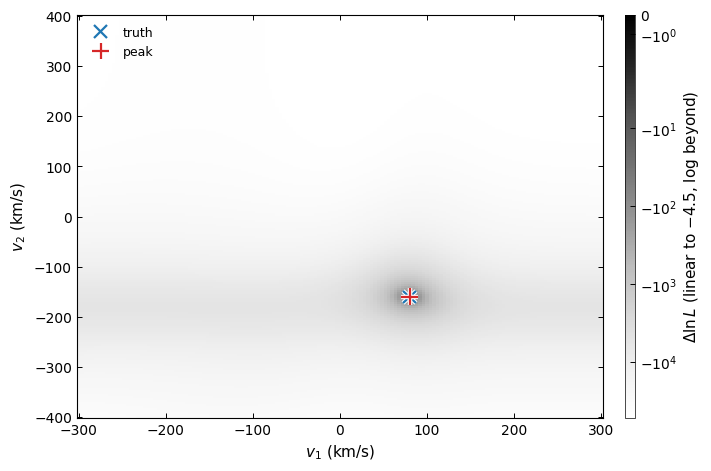

peak: {'v1': 80.0, 'v2': -160.0, 'a1': 0.7024, 'a2': 0.5496, 'chi2': 2566.192, 'chi2_red': 0.9989, 'R': 0.9881}


In [8]:
# Profile and marginal log-likelihood maps from the statistics
res = tf.profile_from_stats(st, v1g, v2g)
# The marginal minus the profile map must equal -1/2 ln det
det_map = np.maximum(st["S11"][:, None]*st["S22"][None, :] - st["A12"]**2, 1e-30)
diff = res["logL_marginal"] - res["logL_profile"]
print("max |(logL_marg - logL_prof) - (-1/2 ln det)| =",
      np.max(np.abs(diff - (-0.5*np.log(det_map)))))

# Plot the profile map (peak black) with the truth and the fitted peak
fig, ax = plt.subplots(figsize=(7.0, 4.6))
logl = res["logL_profile"].T                 # the map is [v1, v2]; v1 along x
mesh = map_image(ax, v1g, v2g, logl, loglike=True)   # Delta lnL, peak black
map_colorbar(mesh, DLNL_LABEL)
mark_truth(ax, v1t, v2t, label="truth")
mark_fit(ax, res["best"]["v1"], res["best"]["v2"], label="peak")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.legend(loc="upper left")
plt.show()
print("peak:", {k: round(x, 4) for k, x in res["best"].items()})

## Summary

Everything the estimator does is now explicit: templates **extended** past the window and shifted
by a **Fourier phase factor** (no wrap reaches the observed pixels, no taper) → a free **offset**
per window, profiled out, so every sum is **centred** → **six sufficient statistics**, with
velocity-dependent template powers → a fixed **quadratic χ²** → a **closed-form 2×2 amplitude
fit** → the **profile/marginal** log-likelihood maps.

- **`02_single_window_fit`**: use `todcor_map` on a realistic single window: read the peak,
  overlay the best-fit spectrum, and validate the CRLB errors against a Monte Carlo.
- **`03_multiwindow_combination`**: pool several line windows of one epoch with
  `combine_stats` (the sufficient-statistic *addition*), see the joint fit break a
  single-window degeneracy, and give each window its own amplitudes.

Full written spec: [`todcor_method.md`](../../../packages/todcor/docs/todcor_method.md).